# Project Background
Nowadays, marketing expenditure in the banking industry is massive, meaning that it is essential for banks to optimize marketing strategies and improve effectiveness. Understanding customers’ need leads to more effective marketing plans, smarter product designs and greater customer satisfaction.

# Main Objective: increase the effectiveness of the bank's telemarketing campaign
This project will enable the bank to develop a more granular understanding of its customer base, predict customers' response to its telemarketing campaign and establish a target customer profile for future marketing plans.

By analyzing customer features, such as demographics and transaction history, the bank will be able to predict customer saving behaviours and identify which type of customers is more likely to make term deposits. The bank can then focus its marketing efforts on those customers. This will not only allow the bank to secure deposits more effectively but also increase customer satisfaction by reducing undesirable advertisements for certain customers.

# TASK #1: IMPORT LIBRABRIES AND DATA CLEANING

## Load the raw data
This dataset is about the direct phone call marketing campaigns, which aim to promote term deposits among existing customers, by a Portuguese banking institution from May 2008 to November 2010. It is publicly available in the UCI Machine Learning Repository, which can be retrieved from http://archive.ics.uci.edu/ml/datasets/Bank+Marketing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
linkname = 'bank_raw.csv'
df1 = pd.read_csv(linkname, sep=';')

In [3]:
# Display the first 5 rows of the DataFrame
df1.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
df1.tail()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


In [5]:
df1.shape

(45211, 17)

In [6]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [7]:
df1.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [8]:
df1.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

There are 45,211 observations in this dataset. Each represents an existing customer that the bank reached via phone calls.

* For each observation, the dataset records **17 input variables** that stand for both qualitative and quantitative attributes of the customer, such as age, job, housing and personal loan status, account balance, and the number of contacts.
* There is **a single binary output variable** that denotes “yes” or “no” revealing the outcomes of the phone calls.

## Clean the dataset

### 1.1 Deal with missing data

There is no missing value in this dataset. Nevertheless, there are values like "unknown", "others", which are helpless just like missing values. Thus, these ambiguous values are removed from the dataset.

In [9]:
# Step 1: Delete the rows where the 'poutcome' column has the value 'other'
condition = df1.poutcome == 'other'
df2 = df1.drop(df1[condition].index, axis=0, inplace=False)

In [10]:
# Step 2: Fill 'unknown' in job and education to 'other'
df2[['job','education']] = df2[['job','education']].replace(['unknown'],'other')

### 1.2 Drop outliers in the column 'balance'

In order to capture the general trend in the dataset, outliers in the column “balance” are dropped. Outliers are defined as the values which are more than three standard deviations away from the mean. In sum, 2556 rows of data were removed.

In [11]:
from scipy.stats import zscore

df2[['balance']].mean()

df2['balance_outliers'] = df2['balance']
df2['balance_outliers']= zscore(df2['balance_outliers'])

condition1 = (df2['balance_outliers']>3) | (df2['balance_outliers']<-3 )
dataset3 = df2.drop(df2[condition1].index, axis = 0, inplace = False)

In [12]:
df4 = dataset3.drop(['balance_outliers'], axis=1)

### 1.3 Creating and transforming data

Some changes were made to the column name, units and data types for easier analysis.

In [13]:
# Step 1: Change column name: 'y' to 'response'ArithmeticError
df4.rename(columns={'y':'response'}, inplace=True)

def convert(df4, new_column, old_column):
    df4[new_column] = df4[old_column].apply(lambda x: 0 if x == 'no' else 1)
    return df4[new_column].value_counts()

convert(df4, 'response_binary', 'response')

response_binary
0    37785
1     4870
Name: count, dtype: int64

In [14]:
# Step 2: Drop the 'contact' column from the DataFrame
df5 = df4.drop('contact', axis=1)

In [15]:
# Step 3: Convert the 'duration' column from seconds to minutes and round to 2 decimal places
df5['duration'] = df5['duration'].apply(lambda n:n/60).round(2)

In [16]:
# Step 4: Change 'month' from words to numbers for easier analysis
lst = [df5]
for column in lst:
    column.loc[column["month"] == "jan", "month_int"] = 1
    column.loc[column["month"] == "feb", "month_int"] = 2
    column.loc[column["month"] == "mar", "month_int"] = 3
    column.loc[column["month"] == "apr", "month_int"] = 4
    column.loc[column["month"] == "may", "month_int"] = 5
    column.loc[column["month"] == "jun", "month_int"] = 6
    column.loc[column["month"] == "jul", "month_int"] = 7
    column.loc[column["month"] == "aug", "month_int"] = 8
    column.loc[column["month"] == "sep", "month_int"] = 9
    column.loc[column["month"] == "oct", "month_int"] = 10
    column.loc[column["month"] == "nov", "month_int"] = 11
    column.loc[column["month"] == "dec", "month_int"] = 12

**1.4 Filtering**

In [17]:
# Step 1: Drop the rows where the 'duration' column has a value less than 5 seconds (0.0833 minutes)
condition2 = (df5['duration'] < 5/60)
df6 = df5.drop(df5[condition2].index, axis=0, inplace=False)

In [18]:
# Step 2:
condition3 = (df6['education'] == 'other')
df7 = df6.drop(df6[condition3].index, axis=0, inplace=False)

# TASK #2: EXPLORATORY DATA ANALYSIS

To obtain a better understanding of the dataset, the distribution of key variables and the relationships among them were plotted.

### 2.1 Visualize the distribution of 'age' and 'balance'

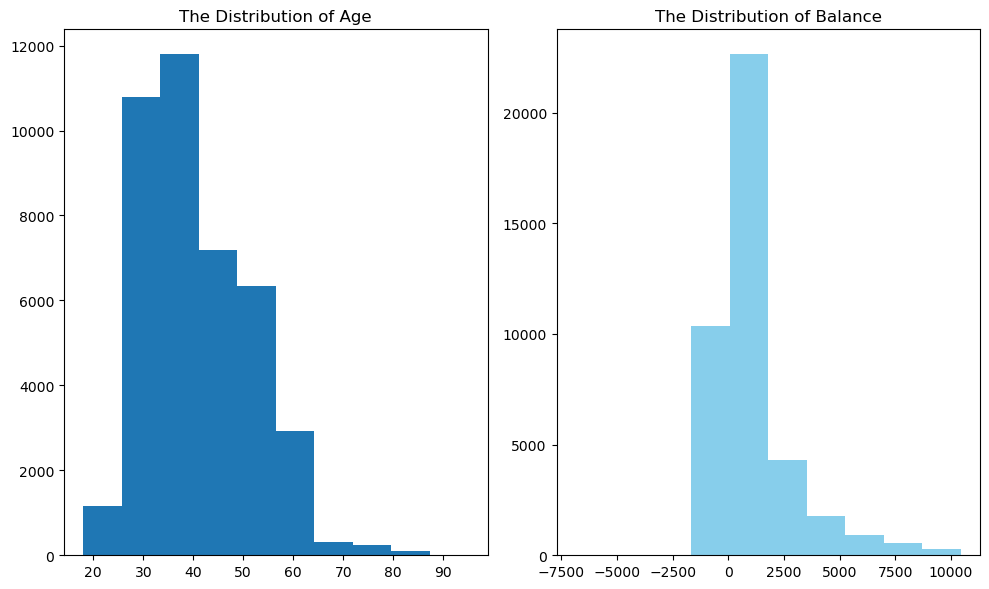

In [19]:
plt.figure(figsize=(10, 6))

plt.subplot(1, 2, 1)
plt.hist(df7['age'])
plt.title('The Distribution of Age')

plt.subplot(1, 2, 2)
plt.hist(df7['balance'], color='skyblue')
plt.title('The Distribution of Balance')

plt.tight_layout()
plt.show()

**The distribution of Age:**
In its telemarketing campaigns, the bank contacted clients across a wide age range, from 18 to 95 years old. However, most customers are concentrated between 30 and 50 years old. The middle 50% of customers fall between 33 and 48 years (25th to 75th percentiles). The age distribution is slightly right-skewed, indicating that there are relatively fewer older customers.

In [20]:
print(df7['balance'].min())
print(df7['balance'].max())
print(df7['balance'].max() - df7['balance'].min())

-6847
10443
17290


**The distribution of Balance:**
After removing outliers from the balance column, the remaining values still have a wide range, from a minimum of -6,847 to a maximum of 10,443 euros, resulting in a range of 17,290 euros. The distribution is strongly right-skewed, with most customers having relatively lower balances and a smaller number having significantly higher balances. This indicates considerable variability in customers' account balances.

### 2.2 Visualize the relationship between 'age' and 'balance'

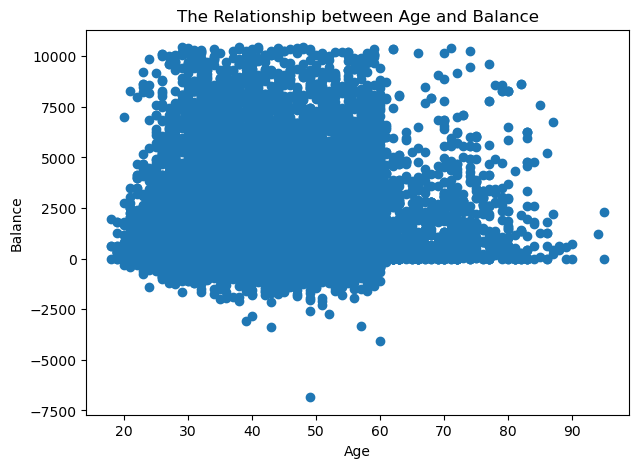

In [21]:
plt.figure(figsize=(7, 5))

plt.scatter(df7['age'], df7['balance'])

plt.title('The Relationship between Age and Balance')
plt.xlabel('Age')
plt.ylabel('Balance')

plt.show()  


Based on this scatter plot, there is no clear relationship between clients' age and their account balance.

However, clients above the age of 60 generally appear to have balances below 5,000, with relatively fewer observations compared to younger clients. There are also some customers with significantly higher or negative balances across different age groups.

### 2.3 Visualize the distribution of 'duration' & 'campaign'

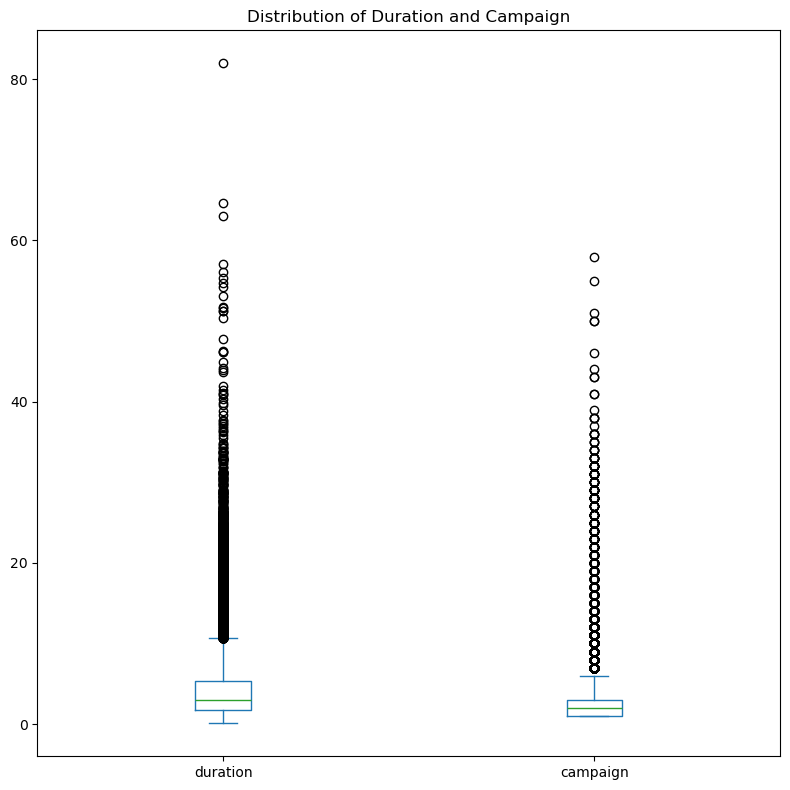

In [33]:
df7[['duration', 'campaign']].plot(
    kind='box',
    figsize=(8, 8),
    layout=(1, 2),
    sharex=False,
    sharey=False
)

plt.title('Distribution of Duration and Campaign')
plt.tight_layout()
plt.show() 

**The distribution of Duration:**

As observed from the box plot, the duration of customer calls has a median of approximately 3 minutes, with an interquartile range of 1.73 to 5.3 minutes. The distribution is strongly right-skewed, indicating that most customer calls are relatively short, while a smaller number of calls last significantly longer. There are numerous outliers above the upper whisker, with some calls exceeding 80 minutes, which may require further investigation.

**The distribution of Campaign:**

The campaign variable has a median of approximately 2 contacts, indicating that half of the customers received around 2 or fewer contacts during the current campaign. Most customers were contacted between 1 and 3 times. However, several extreme outliers are present, with some customers receiving up to 58 contacts. These unusually high contact frequencies may require further investigation.